# Wizualizacja wyników

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.DataFrame({
    "Metoda": [
        "Popularity", "Popularity",
        "MCRS", "MCRS",
        "SASRec", "SASRec"
    ],
    "Filtr": ["Tak", "Nie", "Tak", "Nie", "Tak", "Nie"],
    "P@10": [0.001374, 0.001902, 0.018797, 0.041475, 0.025939, 0.056135],
    "R@10": [0.002456, 0.003152, 0.055447, 0.131978, 0.061299, 0.154968],
    "Trening [s]": [4.14, 4.14, 6.28, 6.28, 1452.87, 1452.87],
    "Ocena [s]": [0.162, 0.109, 41.015, 40.664, 12.275, 11.014],
    "Pred. [ms]": [0.00246, 0.00155, 0.91117, 0.86795, 3.36977, 3.06514]
})

methods = ["Popularity", "MCRS", "SASRec"]
filters = ["Tak", "Nie"]

Wyniki eksperymentów na 10% całego zbioru

In [4]:
df

,Metoda,Filtr,P@10,R@10,Trening [s],Ocena [s],Pred. [ms]
0,Popularity,Tak,0.001374,0.002456,4.14,0.162,0.00246
1,Popularity,Nie,0.001902,0.003152,4.14,0.109,0.00155
2,MCRS,Tak,0.018797,0.055447,6.28,41.015,0.91117
3,MCRS,Nie,0.041475,0.131978,6.28,40.664,0.86795
4,SASRec,Tak,0.025939,0.061299,1452.87,12.275,3.36977
5,SASRec,Nie,0.056135,0.154968,1452.87,11.014,3.06514


Recall@10

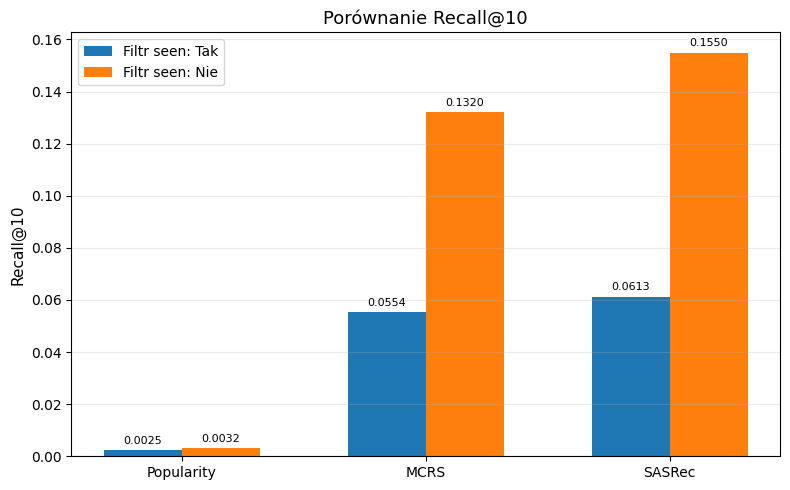

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(methods))
width = 0.32

for i, filt in enumerate(filters):
    vals = [
        df[(df["Metoda"] == m) & (df["Filtr"] == filt)]["R@10"].iloc[0]
        for m in methods
    ]
    bars = ax.bar(
        x + (i - 0.5) * width, vals, width,
        label=f"Filtr seen: {filt}"
    )
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)

ax.set_title("Porównanie Recall@10")
ax.set_ylabel("Recall@10")
ax.set_xticks(x, methods)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Precision@10

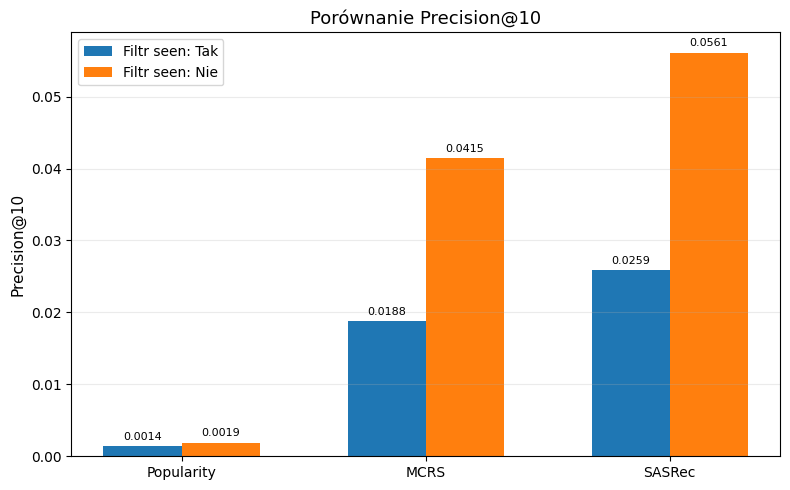

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(methods))
width = 0.32

for i, filt in enumerate(filters):
    vals = [
        df[(df["Metoda"] == m) & (df["Filtr"] == filt)]["P@10"].iloc[0]
        for m in methods
    ]
    bars = ax.bar(
        x + (i - 0.5) * width, vals, width,
        label=f"Filtr seen: {filt}"
    )
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)

ax.set_title("Porównanie Precision@10")
ax.set_ylabel("Precision@10")
ax.set_xticks(x, methods)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Czas predykcji

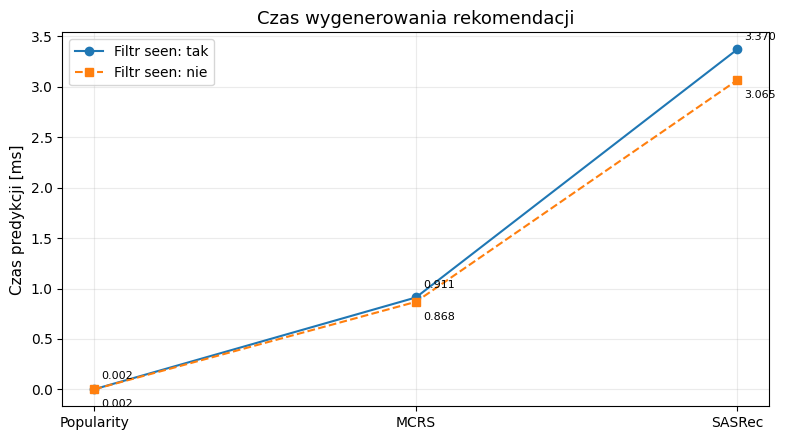

In [11]:
import numpy as np
import matplotlib.pyplot as plt

methods = ["Popularity", "MCRS", "SASRec"]
with_filter = [0.00246, 0.91117, 3.36977]
without_filter = [0.00155, 0.86795, 3.06514]

x = np.arange(len(methods))

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(x, with_filter, "o-", label="Filtr seen: tak")
ax.plot(x, without_filter, "s--", label="Filtr seen: nie")

for i, v in enumerate(with_filter):
    ax.annotate(f"{v:.3f}", (i, v), xytext=(5, 7),
                textcoords="offset points", fontsize=8)

for i, v in enumerate(without_filter):
    ax.annotate(f"{v:.3f}", (i, v), xytext=(5, -13),
                textcoords="offset points", fontsize=8)

ax.set_xticks(x, methods)
ax.set_ylabel("Czas predykcji [ms]")
ax.set_title("Czas wygenerowania rekomendacji")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()